Nama  : Rizki Kurniawan

Nim   : 20240040113

Kelas : Ti 24-J

Matkul : Pengolahan Citra Digital

In [1]:

!pip install imageio numpy scipy matplotlib


In [2]:

import imageio.v2 as imageio
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage
from google.colab import files

print("Library berhasil diimpor!")


Library berhasil diimpor!


Saving WhatsApp Image 2026-10-21 at 08.11.53.jpeg to WhatsApp Image 2026-10-21 at 08.11.53.jpeg
Nama file: WhatsApp Image 2026-10-21 at 08.11.53.jpeg
Ukuran citra: (720, 1600, 3)


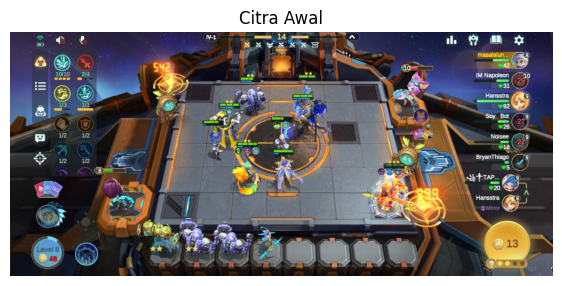

In [3]:

uploaded = files.upload()

nama_file = next(iter(uploaded))
citra_awal = imageio.imread(nama_file)

print("Nama file:", nama_file)
print("Ukuran citra:", citra_awal.shape)

plt.figure(figsize=(7, 5))
plt.imshow(
    citra_awal,
    cmap="gray" if citra_awal.ndim == 2 else None
)
plt.title("Citra Awal")
plt.axis("off")
plt.show()


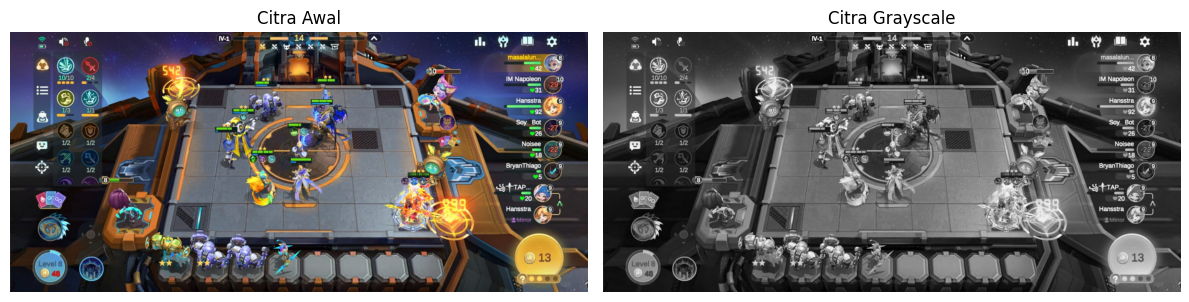

In [4]:

if citra_awal.ndim == 3:
    citra_rgb = citra_awal[..., :3]

    citra_gray = (
        0.299 * citra_rgb[..., 0]
        + 0.587 * citra_rgb[..., 1]
        + 0.114 * citra_rgb[..., 2]
    )
else:
    citra_gray = citra_awal

citra_gray = citra_gray.astype(np.float32)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(citra_awal, cmap="gray" if citra_awal.ndim == 2 else None)
plt.title("Citra Awal")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(citra_gray, cmap="gray", vmin=0, vmax=255)
plt.title("Citra Grayscale")
plt.axis("off")

plt.tight_layout()
plt.show()


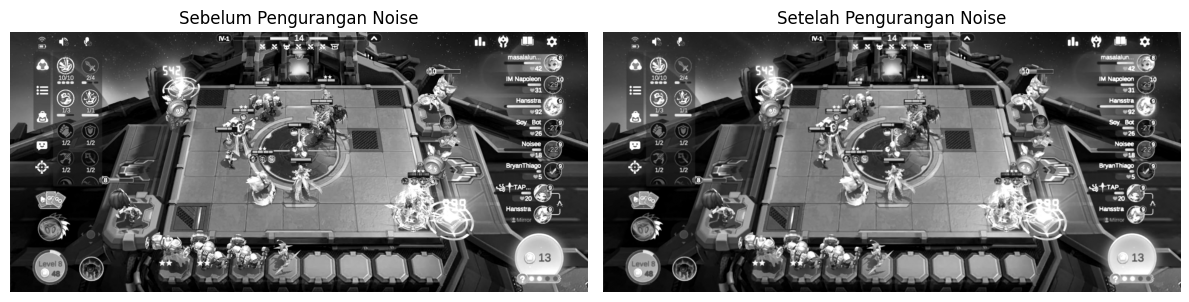

Pengurangan noise berhasil!


In [9]:

# Cell 5: Mengurangi noise

citra_median = ndimage.median_filter(
    citra_kontras, size=3
)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(citra_kontras, cmap="gray")
plt.title("Sebelum Pengurangan Noise")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(citra_median, cmap="gray")
plt.title("Setelah Pengurangan Noise")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Pengurangan noise berhasil!")


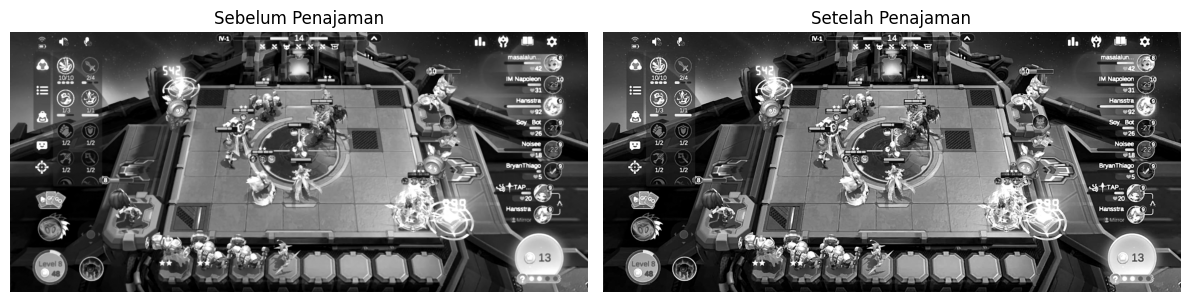

Penajaman citra berhasil!


In [10]:

# Cell 6: Mempertajam citra

citra_input = citra_median.astype(np.float32)

citra_blur = ndimage.gaussian_filter(
    citra_input, sigma=1
)

citra_tajam = (
    citra_input + 1.5 * (citra_input - citra_blur)
)

citra_tajam = np.clip(
    citra_tajam, 0, 255
).astype(np.uint8)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(citra_median, cmap="gray")
plt.title("Sebelum Penajaman")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(citra_tajam, cmap="gray")
plt.title("Setelah Penajaman")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Penajaman citra berhasil!")


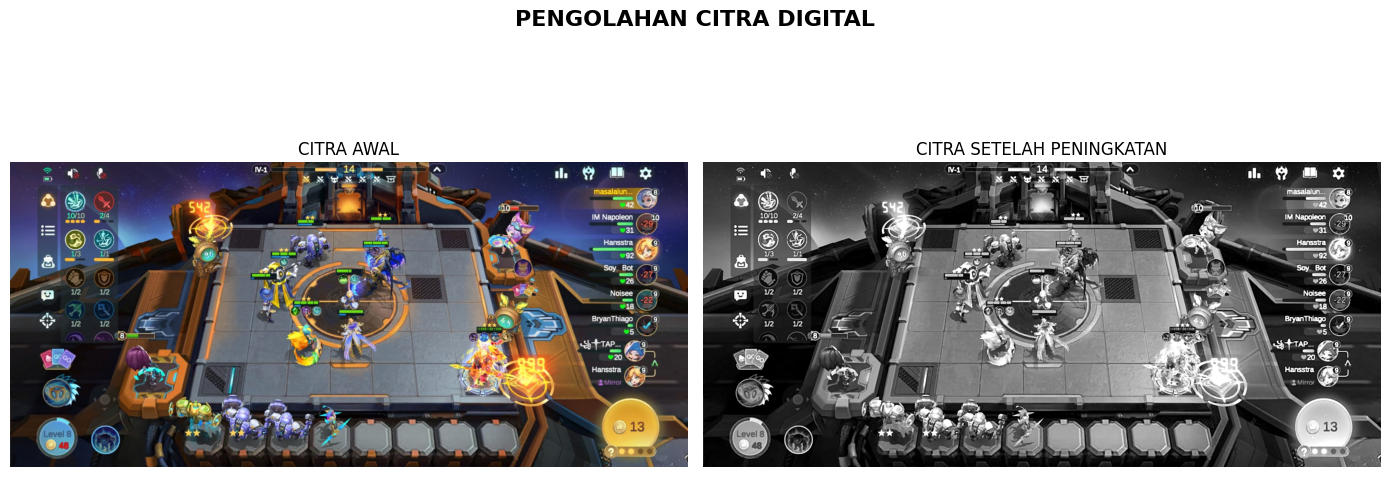

Pengolahan citra selesai!
Hasil perbandingan: hasil_pengolahan_citra.png
Citra hasil: citra_hasil.png


In [11]:

# Cell 7: Perbandingan citra awal dan hasil akhir

plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.imshow(
    citra_awal,
    cmap="gray" if citra_awal.ndim == 2 else None
)
plt.title("CITRA AWAL")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(citra_tajam, cmap="gray", vmin=0, vmax=255)
plt.title("CITRA SETELAH PENINGKATAN")
plt.axis("off")

plt.suptitle(
    "PENGOLAHAN CITRA DIGITAL",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.savefig("hasil_pengolahan_citra.png", dpi=150)
plt.show()

imageio.imwrite("citra_hasil.png", citra_tajam)

print("Pengolahan citra selesai!")
print("Hasil perbandingan: hasil_pengolahan_citra.png")
print("Citra hasil: citra_hasil.png")


In [13]:

files.download("hasil_pengolahan_citra.png")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>